# **Lab 7(A) - Laplacian Filter**

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)




## Apply Laplacian Filter on Image to get Sharp Image

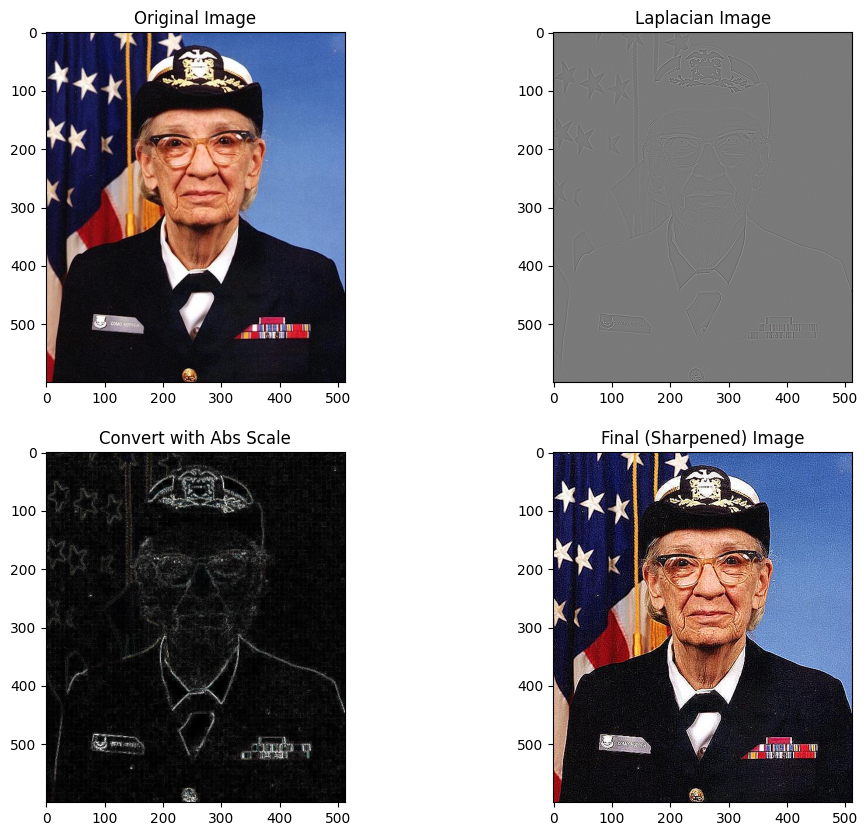

In [2]:
# ================ ( Laplacian Filter ) ===================

# 0. Image file path - a COLOUR image (colour_image.jpg). Put your own colour photo here to use it.
imgFile = "color_image.jpg"

# 1. Load the colour image (OpenCV loads BGR) and convert to RGB for correct display with matplotlib.
#    cv2.filter2D / cv2.Laplacian filter every colour channel independently.
img = cv2.cvtColor(cv2.imread(imgFile), cv2.COLOR_BGR2RGB)

# 2. Manually define the Laplacian Kernel (4-neighbour, centre = -4)
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel: detects diagonal edges as well
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)

# 3. Apply the filter. CV_64F keeps negative values (no clipping)
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Absolute value scaled to 8-bit (only for viewing the edges)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# 5. Sharpening: the centre of the kernel is NEGATIVE, so  g = f - Laplacian(f)
#    Done in float and clipped to [0,255] (uint8 addition would wrap around / overflow)
finalImage = np.clip(img.astype(np.float64) - laplacian_manual, 0, 255).astype(np.uint8)

# 6. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Image')
# signed Laplacian is shifted/scaled to 0-255 only for display
lap_show = cv2.normalize(laplacian_manual, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
plt.subplot(222), plt.imshow(lap_show), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage), plt.title('Final (Sharpened) Image')
plt.show()


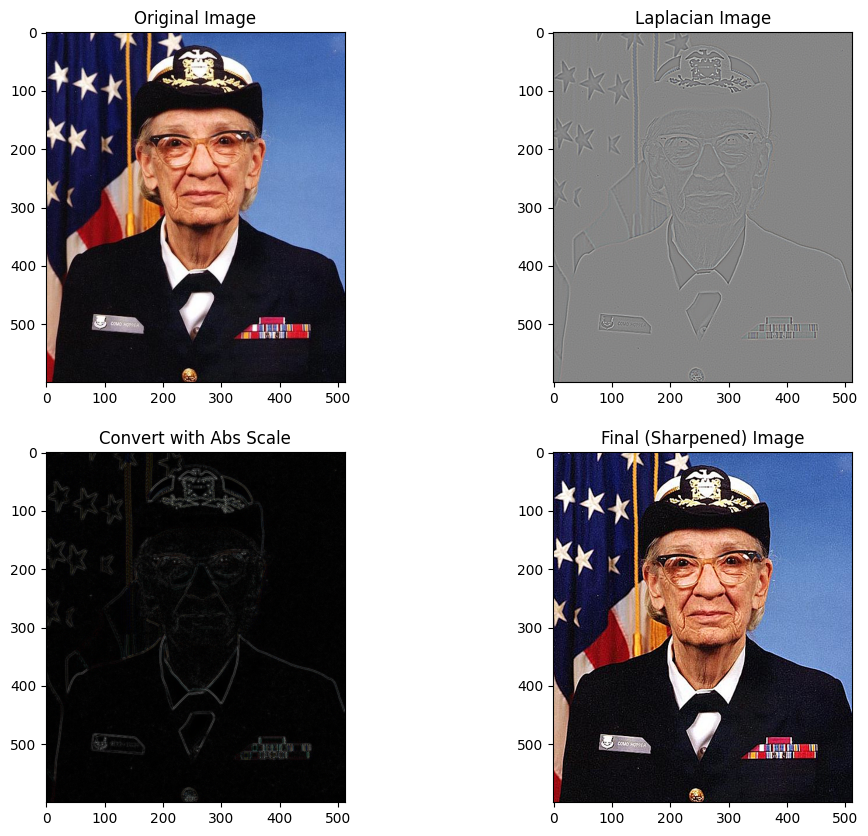

In [3]:
# ================== ( Laplacian Filter - built-in cv2.Laplacian ) ===============

# 1. Optional: Gaussian blur to reduce noise (prevents tiny details being picked up as edges)
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Laplacian (CV_64F keeps both positive and negative responses)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. 8-bit version for viewing
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Sharpen: cv2.Laplacian (ksize=1) uses the same kernel with centre -4  ->  g = f - Laplacian
finalImage2 = np.clip(img.astype(np.float64) - laplacian, 0, 255).astype(np.uint8)

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Image')
lap_show2 = cv2.normalize(laplacian, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
plt.subplot(222), plt.imshow(lap_show2), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2), plt.title('Final (Sharpened) Image')
plt.show()


## Notes
- Because the Laplacian kernel has a **negative centre (-4)**, sharpening is `g = f - ∇²f`. Using `f + |∇²f|` (as in the original template) brightens everything and can overflow `uint8`.
- Both methods (manual `filter2D` kernel and `cv2.Laplacian`) give the same edge map; the second one is computed on a slightly blurred image so it is less sensitive to noise.